# Q1: What is the optimal number of team 3-point attempts per game?

Unit: one row per team per game, 2014-15 to 2025-26. Naive comparisons are
confounded (good teams shoot more threes partly because they are good), so
the models add team-season fixed effects and opponent strength.

**Limit:** the box score has no in-game score margin, so we cannot control for
trailing teams shooting more threes here. Revisit with play-by-play data.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from src.features import load_team_games, vertex_ci
plt.rcParams['figure.dpi'] = 110
g = load_team_games()
print(len(g), 'team-games')
g.groupby('SEASON')['FG3A'].mean().round(1).to_frame('mean 3PA per team-game').T

30878 team-games


SEASON,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26
mean 3PA per team-game,22.6,24.2,27.1,29.1,32.1,34.3,34.6,35.1,34.2,35.0,37.4,36.8


## 1. Raw relationship: win rate and margin by 3PA bucket

,games,win_rate,margin,se
BUCKET,,,,
"(0, 15]",727,0.455,-2.487,0.018
"(15, 20]",2068,0.502,-1.097,0.011
"(20, 25]",4259,0.497,-0.678,0.008
"(25, 30]",6439,0.502,-0.314,0.006
"(30, 35]",7258,0.498,-0.116,0.006
"(35, 40]",5510,0.504,0.490,0.007
"(40, 45]",3033,0.489,0.846,0.009
"(45, 50]",1170,0.533,2.196,0.015
"(50, 100]",414,0.551,4.821,0.024


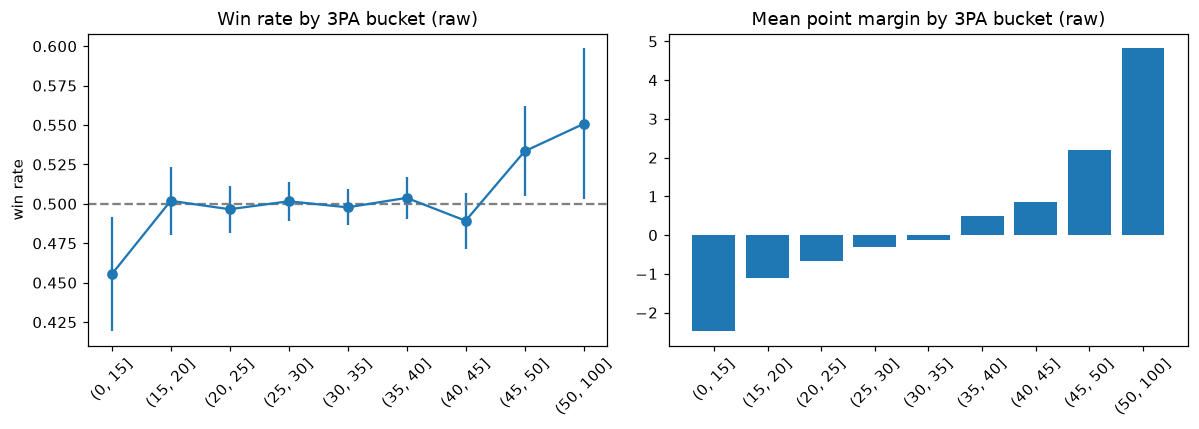

In [2]:
bins = [0, 15, 20, 25, 30, 35, 40, 45, 50, 100]
g['BUCKET'] = pd.cut(g['FG3A'], bins=bins)
t = g.groupby('BUCKET', observed=True).agg(games=('WIN','size'), win_rate=('WIN','mean'), margin=('MARGIN','mean'))
t['se'] = np.sqrt(t.win_rate*(1-t.win_rate)/t.games)
display(t.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = range(len(t))
ax[0].errorbar(x, t.win_rate, yerr=1.96*t.se, fmt='o-'); ax[0].axhline(.5, c='gray', ls='--')
ax[0].set_xticks(x); ax[0].set_xticklabels([str(i) for i in t.index], rotation=45)
ax[0].set_title('Win rate by 3PA bucket (raw)'); ax[0].set_ylabel('win rate')
ax[1].bar(x, t.margin); ax[1].set_xticks(x); ax[1].set_xticklabels([str(i) for i in t.index], rotation=45)
ax[1].set_title('Mean point margin by 3PA bucket (raw)')
plt.tight_layout(); plt.show()

## 2. Era check: the raw curve by period

League volume rose from ~22 to ~37 per team-game, so 'many threes' means different things in different years.

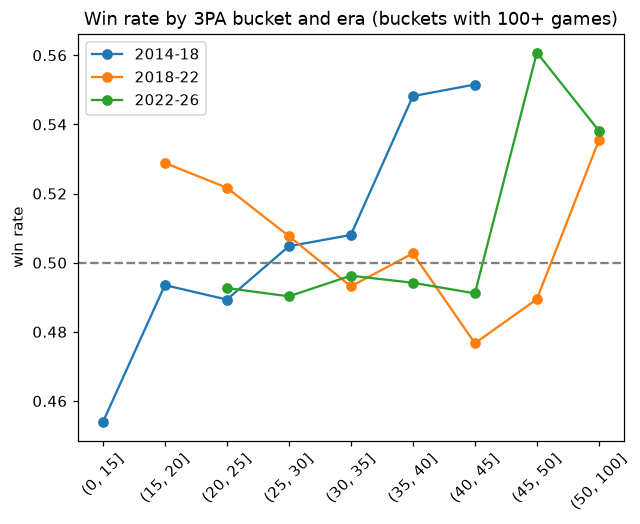

In [3]:
g['ERA'] = pd.cut(g['SEASON'].str[:4].astype(int), [2013, 2017, 2021, 2025], labels=['2014-18','2018-22','2022-26'])
for era, d in g.groupby('ERA', observed=True):
    r = d.groupby(pd.cut(d.FG3A, bins), observed=True)['WIN'].agg(['mean','size'])
    r = r[r['size'] >= 100]
    plt.plot([str(i) for i in r.index], r['mean'], 'o-', label=str(era))
plt.axhline(.5, c='gray', ls='--'); plt.xticks(rotation=45); plt.legend(); plt.ylabel('win rate')
plt.title('Win rate by 3PA bucket and era (buckets with 100+ games)'); plt.show()

## 3. Models

All use standard errors clustered by game (each game appears twice).

- **Total effect:** `WIN ~ FG3A + FG3A^2` with team-season fixed effects, opponent strength and home. Everything that moves with 3PA (accuracy, shot mix) is allowed to flow through.
- **Full box-score model:** adds 3P%, 2PA, FTA, TOV, OREB, pace. This holds those constant, so it asks what an *extra attempt at fixed accuracy* does. Note 3P% in the same game is partly luck, which is an outcome not a choice.

In [4]:
def fit(formula, kind='logit'):
    f = smf.logit if kind == 'logit' else smf.ols
    return f(formula, data=g).fit(disp=0, cov_type='cluster', cov_kwds={'groups': g['GAME_ID']})

fe = 'C(TEAM_SEASON) + OPP_STRENGTH + HOME'
models = {
 'logit_total': fit(f'WIN ~ FG3A + FG3A_SQ + {fe}'),
 'logit_full' : fit(f'WIN ~ FG3A + FG3A_SQ + FG3_PCT + FG2A + FTA + TOV + OREB + POSS + {fe}'),
 'ols_total'  : fit(f'MARGIN ~ FG3A + FG3A_SQ + {fe}', 'ols'),
 'ols_full'   : fit(f'MARGIN ~ FG3A + FG3A_SQ + FG3_PCT + FG2A + FTA + TOV + OREB + POSS + {fe}', 'ols'),
}
rows = []
for k, m in models.items():
    p, se = m.params, m.bse
    est, lo, hi = vertex_ci(p, m.cov_params(), 'FG3A', 'FG3A_SQ')
    rows.append(dict(model=k, b_FG3A=p['FG3A'], se=se['FG3A'], b_FG3A_SQ=p['FG3A_SQ'], se_sq=se['FG3A_SQ'],
                     p_sq=m.pvalues['FG3A_SQ'], vertex=est, ci_lo=lo, ci_hi=hi))
res = pd.DataFrame(rows).set_index('model'); res.round(4)

,b_FG3A,se,b_FG3A_SQ,se_sq,p_sq,vertex,ci_lo,ci_hi
model,,,,,,,,
logit_total,-0.0427,0.0105,0.0004,0.0002,0.0059,49.8112,41.6314,89.7911
logit_full,-0.1602,0.0175,0.0005,0.0002,0.0028,154.6012,102.4408,378.5256
ols_total,-0.0843,0.0613,0.0023,0.0009,0.0127,18.3122,-24.7424,26.3236
ols_full,-0.0773,0.0849,0.0020,0.0009,0.0234,19.7663,-60.7295,62.6528


A vertex only means 'the optimum' if the squared term is negative and significant. If it is not, the data do not show diminishing returns in this range, and the vertex CI will be very wide or unbounded.

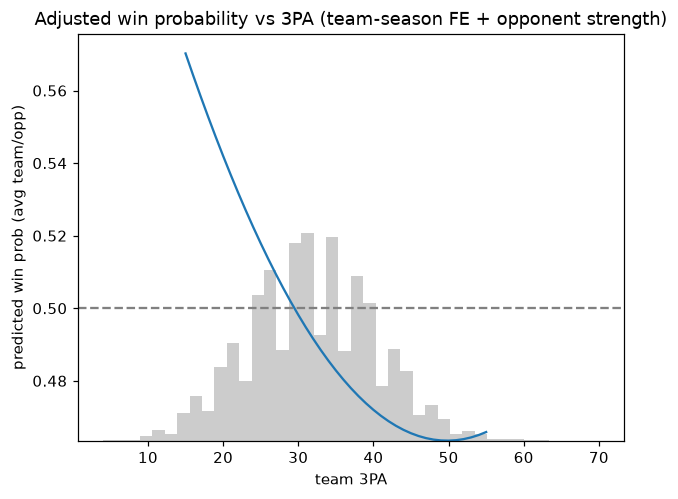

15    0.570
20    0.542
25    0.518
30    0.498
35    0.483
40    0.472
45    0.466
50    0.464
55    0.466
dtype: float64

In [5]:
# Predicted effect of 3PA on win probability, holding other things at their mean (total-effect model)
m = models['logit_total']
base = g.sample(5000, random_state=0).copy()
xs = np.arange(15, 56)
curve = []
for x in xs:
    d = base.copy(); d['FG3A'] = x; d['FG3A_SQ'] = x**2
    curve.append(m.predict(d).mean())
curve = np.array(curve)
plt.plot(xs, curve); plt.axhline(.5, c='gray', ls='--')
plt.hist(g.FG3A, bins=40, density=True, alpha=.2, color='k', label='share of team-games (scaled)', bottom=curve.min())
plt.xlabel('team 3PA'); plt.ylabel('predicted win prob (avg team/opp)')
plt.title('Adjusted win probability vs 3PA (team-season FE + opponent strength)'); plt.show()
pd.Series(curve, index=xs).iloc[::5].round(3)

## 4. Does the optimum shift by era? (total-effect OLS on margin, by period)

In [6]:
out = []
for era, d in g.groupby('ERA', observed=True):
    mm = smf.ols(f'MARGIN ~ FG3A + FG3A_SQ + {fe}', data=d).fit(cov_type='cluster', cov_kwds={'groups': d['GAME_ID']})
    est, lo, hi = vertex_ci(mm.params, mm.cov_params(), 'FG3A', 'FG3A_SQ')
    out.append(dict(era=era, b_sq=mm.params['FG3A_SQ'], p_sq=mm.pvalues['FG3A_SQ'], mean_3PA=d.FG3A.mean(), vertex=est, lo=lo, hi=hi))
pd.DataFrame(out).set_index('era').round(3)

,b_sq,p_sq,mean_3PA,vertex,lo,hi
era,,,,,,
2014-18,0.003,0.130,25.744,15.402,-79.225,93.497
2018-22,0.004,0.081,33.998,30.139,-1.888,50.778
2022-26,0.002,0.244,35.864,13.140,-192.764,228.449


## 5. Gradient boosting robustness check (no assumed curve)

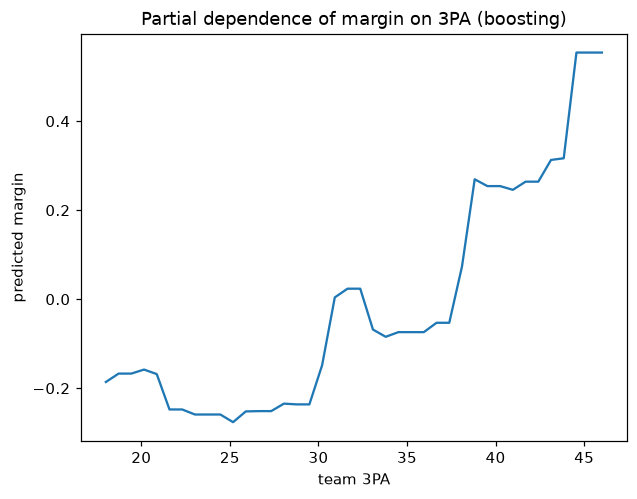

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import partial_dependence
feats = ['FG3A','FG3_PCT','FG2A','FTA','TOV','OREB','POSS','HOME','OPP_STRENGTH','TEAM_STRENGTH']
d = g.dropna(subset=feats+['MARGIN']).copy()
d[feats] = d[feats].astype(float)
# team-strength is leave-one-game-out, so it is a fair control
gb = HistGradientBoostingRegressor(max_depth=3, learning_rate=.05, max_iter=300, random_state=0).fit(d[feats], d['MARGIN'])
pdp = partial_dependence(gb, d[feats], ['FG3A'], grid_resolution=40)
plt.plot(pdp['grid_values'][0], pdp['average'][0]); plt.xlabel('team 3PA'); plt.ylabel('predicted margin')
plt.title('Partial dependence of margin on 3PA (boosting)'); plt.show()

## 6. High-volume extremes (sanity check)

In [8]:
s = g.groupby(['TEAM_NAME','SEASON']).agg(games=('WIN','size'), FG3A=('FG3A','mean'), FG3_PCT=('FG3M', 'sum'),
                                          FG3A_tot=('FG3A','sum'), win_pct=('WIN','mean'), margin=('MARGIN','mean'))
s['FG3_PCT'] = s['FG3_PCT']/s['FG3A_tot']
s.drop(columns='FG3A_tot').sort_values('FG3A', ascending=False).head(8).round(3)

games    FG3A  FG3_PCT  win_pct  margin
TEAM_NAME             SEASON                                          
Boston Celtics        2024-25     93  47.183    0.368    0.720   8.688
Houston Rockets       2019-20     84  45.500    0.348    0.583   2.643
                      2018-19     93  45.065    0.357    0.634   4.581
Golden State Warriors 2025-26     82  44.098    0.356    0.451  -0.561
Charlotte Hornets     2025-26     82  43.280    0.378    0.537   4.829
Utah Jazz             2020-21     83  43.108    0.392    0.699   7.916
Golden State Warriors 2022-23     95  43.084    0.379    0.526   1.537
Boston Celtics        2025-26     89  42.461    0.364    0.663   7.315

## Reading the results

See the tables above. Key cautions:

- Team-season fixed effects remove the 'good teams shoot more' problem between teams but not within a team over games (a team shoots more when trailing).
- In-game score state is not in this data. Play-by-play for 2025-26 allows a follow-up.
- Estimates describe the observed range (about 15-55 3PA). Do not extrapolate beyond it.